In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
df=pd.read_excel("for anova (1).xlsx",sheet_name="trtmt for ANOVA")
xls=pd.ExcelFile("for anova (1).xlsx")
print(xls.sheet_names)
df.head()
# use for multiple sheet and you want to specify,do not use the print function it makes it scattered,call your df function straight

['trtmt for ANOVA']


,GENOTYPE,trtmt,year,REP,%Survival,elongation,%elongation,DAYS_FLW,sub plt hght on field,Tiller_No,Panicle_No,Yield (ton/Ha),%yield reduction
0,FARO 44,sss,2020,1,20.0,10.2,40.476190,105,87.0,7.0,3.0,0.107001,96.903879
1,FARO 52,sss,2020,1,30.0,12.2,60.098522,109,112.0,8.0,5.0,0.033000,99.270071
2,FARO 57,sss,2020,1,10.0,13.4,62.325581,118,123.0,10.0,5.0,0.033000,98.898212
3,FARO 60,sss,2020,1,20.0,14.2,64.253394,111,131.0,7.0,4.0,0.032500,99.495999
4,UPIA 3,sss,2020,1,15.0,14.5,88.414634,115,81.0,5.0,4.0,0.032050,98.969926


In [4]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl.chart
import os
import statsmodels.api as sm
df= pd.read_excel('for anova (1).xlsx')
df



,GENOTYPE,trtmt,year,REP,%Survival,elongation,%elongation,DAYS_FLW,sub plt hght on field,Tiller_No,Panicle_No,Yield (ton/Ha),%yield reduction
0,FARO 44,sss,2020,1,20.000000,10.2,40.476190,105,87.00,7.0,3.0,0.107001,96.903879
1,FARO 52,sss,2020,1,30.000000,12.2,60.098522,109,112.00,8.0,5.0,0.033000,99.270071
2,FARO 57,sss,2020,1,10.000000,13.4,62.325581,118,123.00,10.0,5.0,0.033000,98.898212
3,FARO 60,sss,2020,1,20.000000,14.2,64.253394,111,131.00,7.0,4.0,0.032500,99.495999
4,UPIA 3,sss,2020,1,15.000000,14.5,88.414634,115,81.00,5.0,4.0,0.032050,98.969926
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,SAMBA MASHI SUB1,Dss,2019,3,94.736842,7.8,33.766234,139,55.33,7.8,5.1,1.868580,54.354408
86,N-L52,Dss,2019,3,0.000000,-37.1,-100.000000,0,0.00,0.0,0.0,0.000000,100.000000
87,TOS 6454,Dss,2019,3,88.888889,17.4,55.591054,121,105.03,6.7,4.1,1.779606,50.849510
88,FARO 66,Dss,2019,3,90.000000,10.0,40.160643,117,64.83,10.2,5.0,2.740248,46.500970


In [23]:
import pandas as pd

# Load your dataset
df = pd.read_excel("for anova (1).xlsx")

# Automatically check column types
print(df.dtypes)


GENOTYPE                  object
trtmt                     object
year                       int64
REP                        int64
%Survival                float64
elongation               float64
%elongation              float64
DAYS_FLW                   int64
sub plt hght on field    float64
Tiller_No                float64
Panicle_No               float64
Yield (ton/Ha)           float64
%yield reduction         float64
dtype: object


Numeric columns: ['year', 'REP', '%Survival ', 'elongation', '%elongation', 'DAYS_FLW', 'sub plt hght on field', 'Tiller_No ', 'Panicle_No', 'Yield (ton/Ha)', '%yield reduction']
Categorical columns: ['GENOTYPE', 'trtmt']


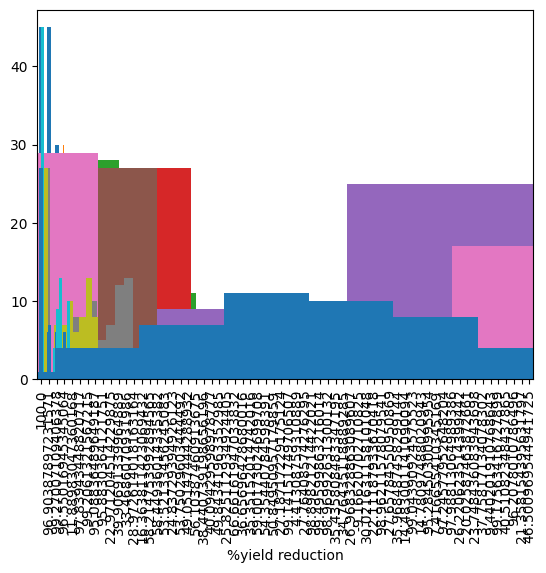

In [39]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
for col in numeric_cols:
    #print(f"Analyzing numeric column: {col}")
   # print(df[col].describe())  # basic statistics
    
    # optional histogram
    #df[numeric_cols].hist(figsize=(18, 14), bins=10)
    #plt.suptitle("Distribution of Numeric Columns", fontsize=44)
    #plt.show()
    df[col].hist()
   # for col in categorical_cols:
   # print(f"Analyzing categorical column: {col}")
      #  print(df[col].value_counts())  # frequency of each category
    
    # optional bar chart
    df[col].value_counts().plot(kind='bar')


In [ ]:

from pandas.api import types as ptypes

def infer_column_type(series, unique_thresh=20):
    if ptypes.is_datetime64_any_dtype(series):
        return "datetime"
    if ptypes.is_bool_dtype(series):
        return "categorical"
    if ptypes.is_numeric_dtype(series):
        if series.nunique(dropna=True) <= unique_thresh:
            return "categorical_numeric"   # discrete numeric -> treat like category
        else:
            return "numerical"
    return "categorical"

col_types = {col: infer_column_type(df[col]) for col in df.columns}
import pandas as pd
print(pd.Series(col_types))



GENOTYPE                         categorical
trtmt                            categorical
year                     categorical_numeric
REP                      categorical_numeric
%Survival                          numerical
elongation                         numerical
%elongation                        numerical
DAYS_FLW                           numerical
sub plt hght on field              numerical
Tiller_No                          numerical
Panicle_No                         numerical
Yield (ton/Ha)                     numerical
%yield reduction                   numerical
dtype: object


In [19]:

import pandas as pd
import scipy.stats as stats

df = pd.read_excel("for anova (1).xlsx")
# Clean column names: remove spaces, % signs, lowercase everything
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.replace("%", "percent")
df.columns = df.columns.str.lower()
print(df.columns.tolist())

['genotype', 'trtmt', 'year', 'rep', 'percentsurvival', 'elongation', 'percentelongation', 'days_flw', 'sub_plt_hght_on_field', 'tiller_no', 'panicle_no', 'yield_(ton/ha)', 'percentyield_reduction']


F-statistic: 20.503483013440597
P-value: 3.90104083087231e-20
✅ Yield differs significantly between GENOTYPEs


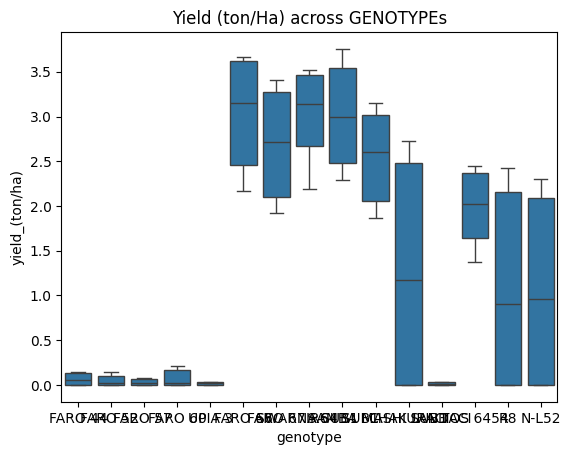

In [22]:
import scipy.stats as stats

# Dependent variable
yields = df["yield_(ton/ha)"]

# Group variable
genotypes = df["genotype"]

# Create a list of arrays, one per genotype
groups = [yields[genotypes == g] for g in genotypes.unique()]
f_stat, p_value = stats.f_oneway(*groups)  # * unpacks the list into arguments

print("F-statistic:", f_stat)
print("P-value:", p_value)

# Interpretation
if p_value < 0.05:
    print("✅ Yield differs significantly between GENOTYPEs")
else:
    print("❌ No significant difference in Yield between GENOTYPEs")
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x="genotype", y="yield_(ton/ha)", data=df)
plt.title("Yield (ton/Ha) across GENOTYPEs")
plt.show()



Numeric columns: ['year', 'REP', '%Survival ', 'elongation', '%elongation', 'DAYS_FLW', 'sub plt hght on field', 'Tiller_No ', 'Panicle_No', 'Yield (ton/Ha)', '%yield reduction']
Categorical columns: ['GENOTYPE', 'trtmt']


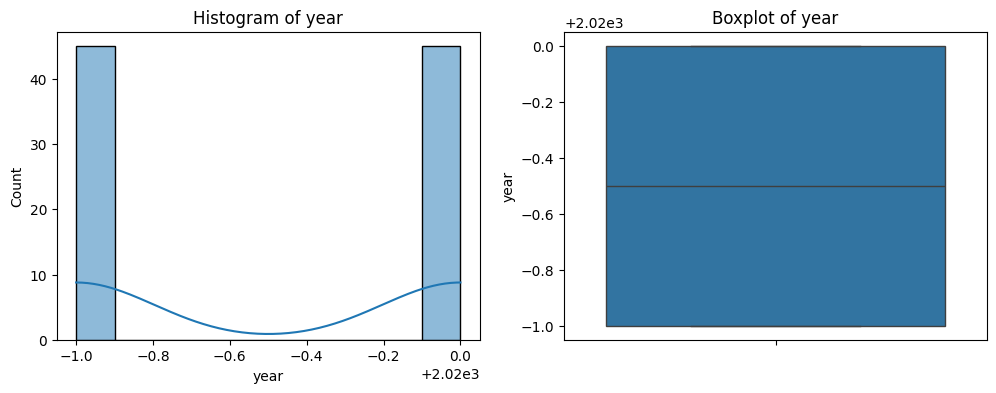

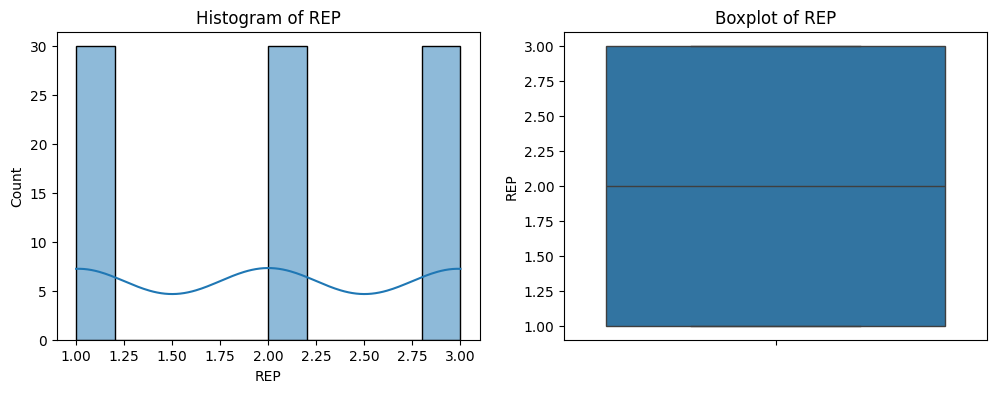

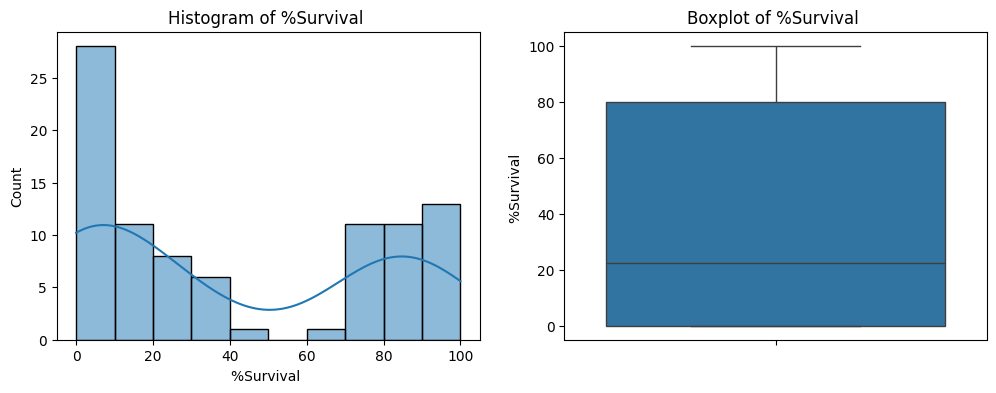

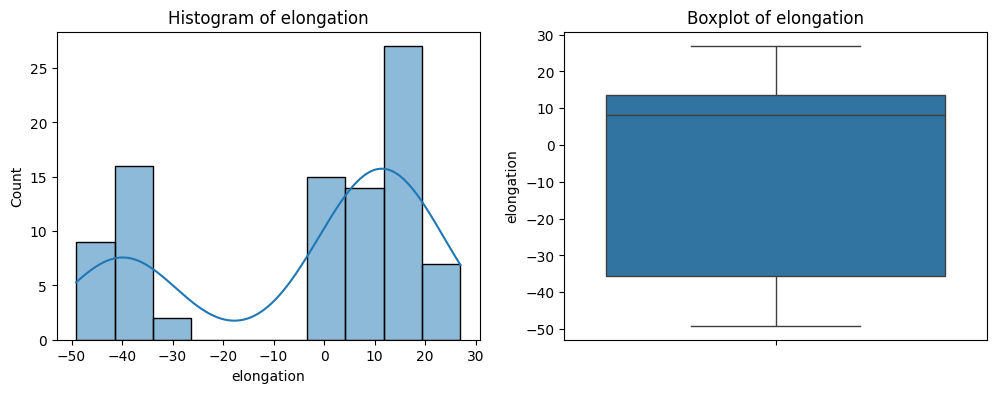

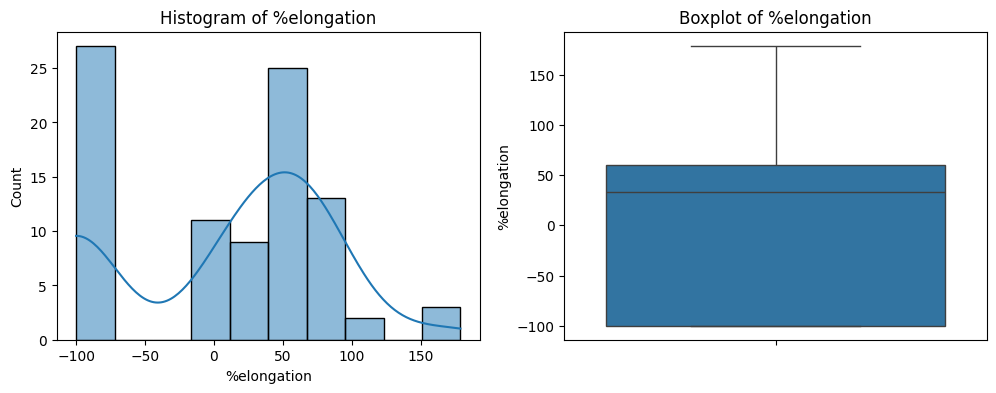

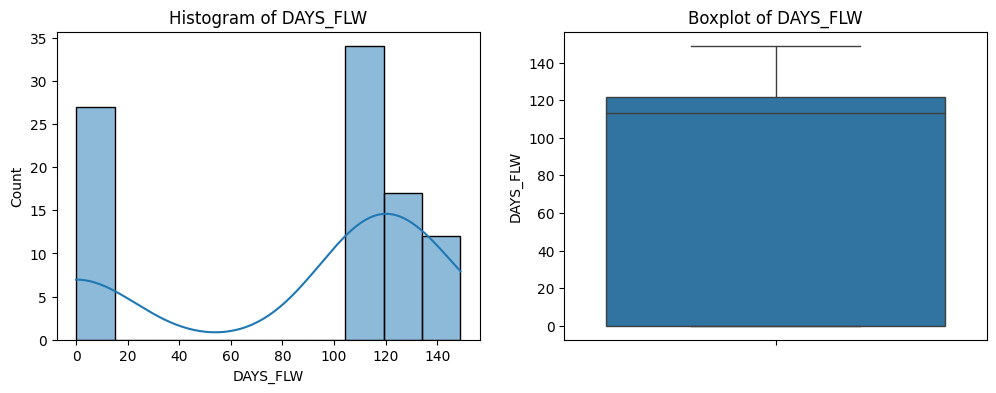

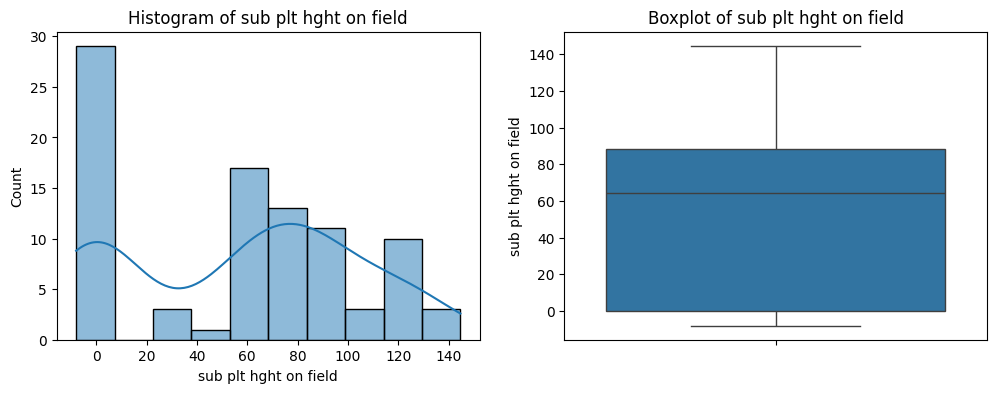

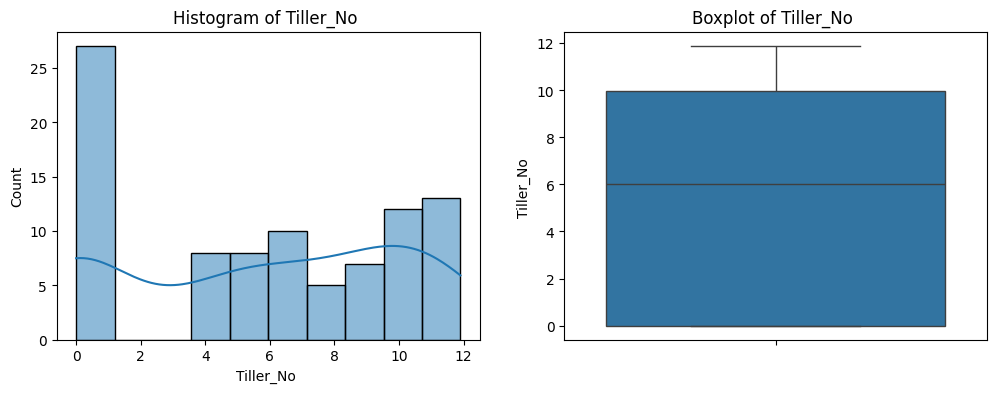

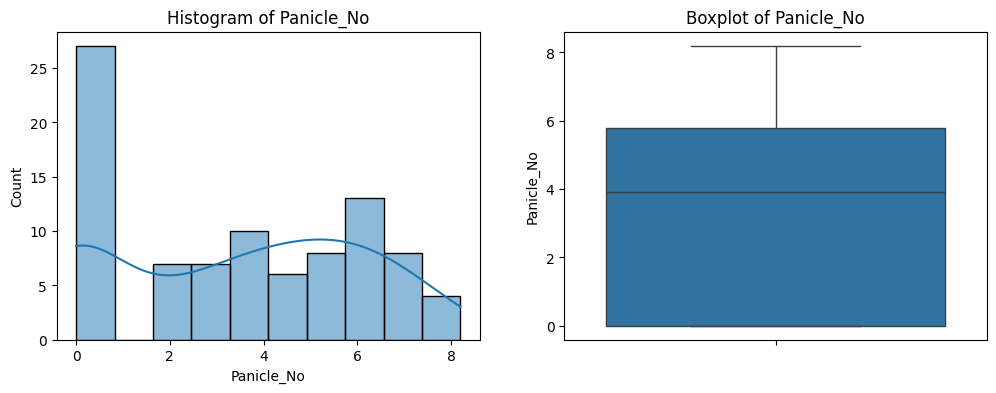

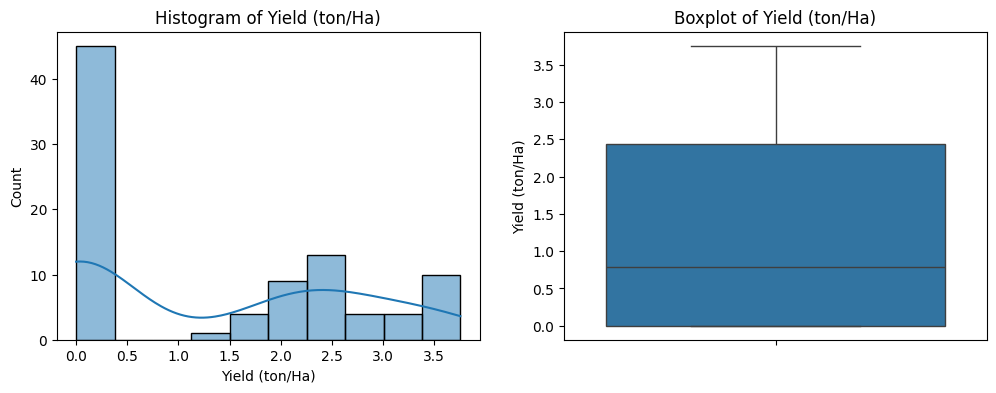

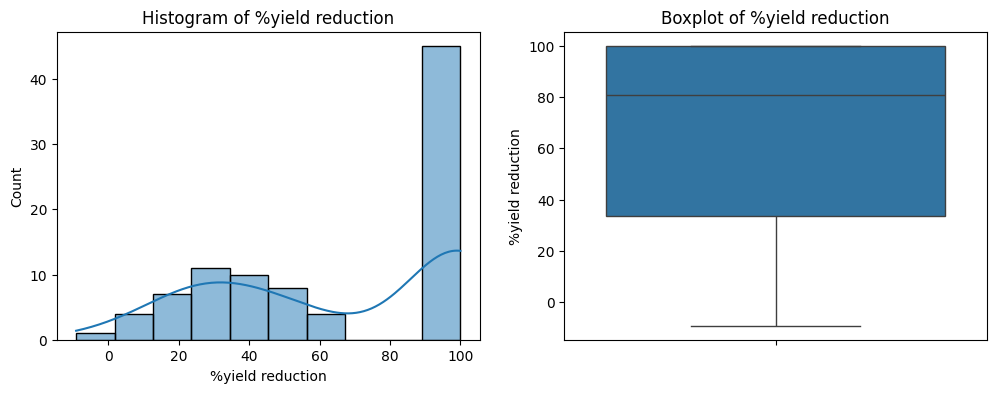

In [2]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
df = pd.read_excel("for anova (1).xlsx")

# Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

for col in numeric_cols:
    plt.figure(figsize=(12,4))
    
    # Histogram
    plt.subplot(1,2,1)
    sns.histplot(df[col], kde=True, bins=10)
    plt.title(f"Histogram of {col}")
    
    # Boxplot
    plt.subplot(1,2,2)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
    
    plt.show()


Numeric columns: ['year', 'REP', '%Survival ', 'elongation', '%elongation', 'DAYS_FLW', 'sub plt hght on field', 'Tiller_No ', 'Panicle_No', 'Yield (ton/Ha)', '%yield reduction']
Categorical columns: ['GENOTYPE', 'trtmt']


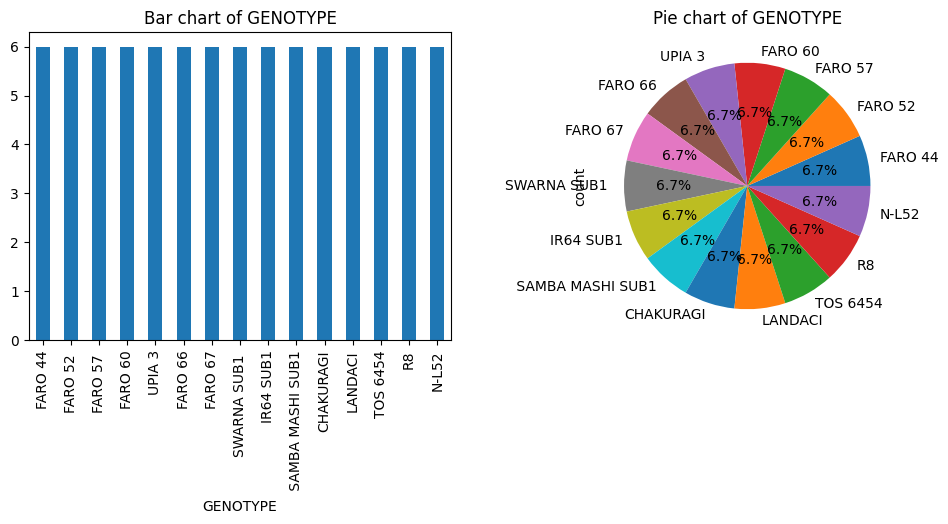

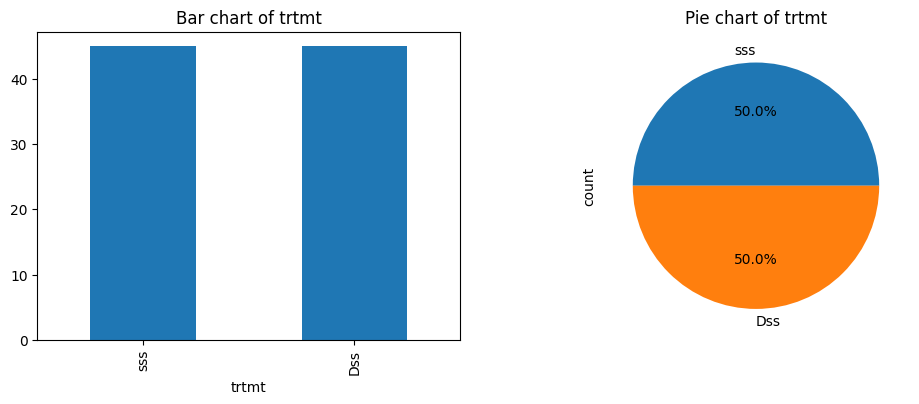

In [3]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
df = pd.read_excel("for anova (1).xlsx")

# Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

for col in categorical_cols:
    plt.figure(figsize=(12,4))
    
    # Bar chart
    plt.subplot(1,2,1)
    df[col].value_counts().plot(kind='bar')
    plt.title(f"Bar chart of {col}")
    
    # Pie chart
    plt.subplot(1,2,2)
    df[col].value_counts().plot(kind='pie', autopct='%1.1f%%')
    plt.title(f"Pie chart of {col}")
    
    plt.show()


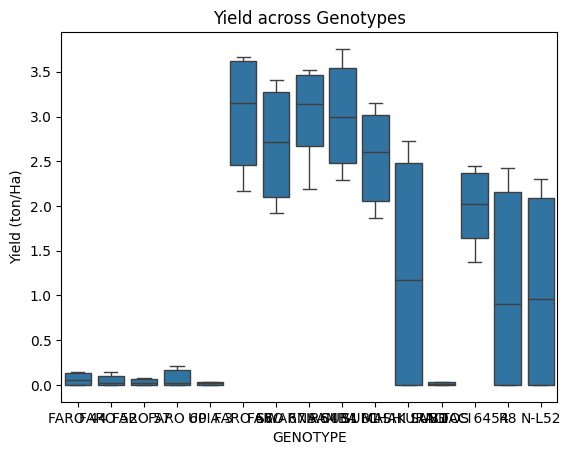

F-statistic: 20.503483013440597
P-value: 3.90104083087231e-20


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x="GENOTYPE", y="Yield (ton/Ha)", data=df)
plt.title("Yield across Genotypes")
plt.show()
from scipy import stats

groups = [df[df['GENOTYPE']==g]['Yield (ton/Ha)'].dropna() for g in df['GENOTYPE'].unique()]
f_stat, p_val = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_val)


In [ ]:
## performing anova for all numeric input.that is no strings or whatever


import pandas as pd
import scipy.stats as stats

df = pd.read_excel("for anova (1).xlsx")
GENOTYPE = df["GENOTYPE"].dropna()
trtmt = df["trtmt"].dropna()
year = df["year"].dropna()
REP   = df["REP"].dropna()
Survival_percent = df["%Survival "].dropna()
elongation = df["elongation"].dropna()
elongation_percent = df["%elongation"].dropna()
DAYS_FLW = df["DAYS_FLW"].dropna()
sub_plt_hght_on_field= df["sub plt hght on field"].dropna()
Tiller_No= df["Tiller_No "].dropna()
Panicle_No= df["Panicle_No"].dropna()  
yield_ton_ha= df["Yield (ton/Ha)"].dropna()
yield_reduction_percent= df["%yield reduction"].dropna()
f_stat,p_value = stats.f_oneway()[GENOTYPE, trtmt, year, REP,
                                   Survival_percent , elongation, elongation_percent, 
                                   DAYS_FLW, sub_plt_hght_on_field, Tiller_No , 
                                   Panicle_No, yield_ton_ha, yield_reduction_percent
                                   ]
print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("f-statistics:", f_stat)
else:
    print("no significant difference between groups")
